# Diabetes Progression: Regression and Exploratory Classification
**Senay Teweldebrhan — Student ID: 9120588**  
**Machine Learning Assignment | Parts 1, 2, and 3**

## Abstract
This study predicts a quantitative measure of disease progression one year after baseline using the scikit-learn Diabetes dataset. It evaluates six BMI-only polynomial regressions and eight multivariate candidates on a fixed 75% / 10% / 15% patient split. The BMI-only degree-5 model is selected by validation MAE and achieves test R² **0.267**, MAE **51.75**, and MAPE **43.03%**. The multivariate degree-2 Ridge polynomial is selected by the same criterion and achieves test R² **0.433**, MAE **43.67**, and MAPE **36.56%**. Polynomial complexity beyond degree 2 worsens validation performance in the multivariate experiment. Logistic regression requires a separate, explicitly defined binary outcome; two logistic classifiers are therefore evaluated on an exploratory above-training-median event, with a documented probability-to-score decoder for the required regression-metric comparison. No clinical risk cutoff or deployment readiness is inferred.

## Report organization
- **Part 1, Steps 1–5:** data, problem framing, EDA, cleaning, and patient allocation.
- **Part 2, Steps 6–14:** six BMI polynomial models, validation selection, test evaluation, fitted equation, prediction, parameter counts, and failure analysis.
- **Part 3:** two multivariate polynomials, two trees, two kNNs, and two logistic classifiers; comparison, selection, test results, prediction rules, examples, parameter counts, and conclusions.

The notebook presents the analysis and interpretation. Reusable implementations reside in `src/data.py`, `src/models.py`, `src/evaluation.py`, `src/experiment.py`, and `src/plots.py`. This separation follows the modular ML Pipeline Pattern discussed in the KNN workshop.


## Reproducible environment and source modules
Core experiments use Python 3.12, a fixed random seed of 42, and the dependency versions printed below. No external dataset download, database, or credentials are required. The notebook locates the project root from either the root directory or its `notebooks/` directory.


In [1]:
from pathlib import Path
import sys
import importlib.metadata

PROJECT_ROOT = next(
    (path for path in [Path.cwd(), Path.cwd().parent] if (path / 'src' / 'experiment.py').is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('The project src/ directory is required alongside notebooks/.')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.polynomial import Polynomial

from src.data import (
    TARGET, clean_dataset, iqr_summary, load_dataset,
    quality_report, split_dataset, split_summary, training_frame,
)
from src.evaluation import polynomial_coefficients
from src.experiment import export_results, run_experiment, safe_name
from src.models import LogisticScoreAdapter
from src.plots import (
    configure_plots, plot_bmi_fit, plot_correlations,
    plot_histograms, plot_residuals, plot_scatter, save_figure,
)

pd.set_option('display.max_columns', 16)
pd.set_option('display.precision', 3)
configure_plots()
TABLE_DIR = PROJECT_ROOT / 'reports' / 'tables'
FIGURE_DIR = PROJECT_ROOT / 'reports' / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

versions = {'Python': sys.version.split()[0]}
for package in ['numpy', 'pandas', 'scipy', 'matplotlib', 'scikit-learn']:
    versions[package] = importlib.metadata.version(package)
display(pd.Series(versions, name='Version').to_frame())


,Version
Python,3.14.6
numpy,2.3.5
pandas,2.3.3
scipy,1.17.1
matplotlib,3.10.9
scikit-learn,1.8.0


# Part 1 — Data and problem definition
## 1. Get the data
The official dataset description identifies **442 patients with diabetes**, ten baseline measurements, and a quantitative progression score observed **one year after baseline** [1, 2]. The patient-level outcome is not a diabetes diagnosis and is not a probability. Its clinical units and an actionable screening threshold are not specified.

`load_diabetes(as_frame=True, scaled=False)` returns labelled pandas objects and preserves the supplied feature values. The default `return_X_y=False` retains the Bunch metadata and description; `return_X_y=True` would instead return `(X, y)`. The default `scaled=True` centers and rescales features using the entire dataset and the square root of its sample count. Loading unscaled values allows all learned normalization to be fitted inside training pipelines.


In [2]:
df, dataset_description = load_dataset()
feature_names = df.drop(columns=TARGET).columns.tolist()
print(f'Patients: {len(df)} | Baseline predictors: {len(feature_names)} | Response columns: 1')
display(pd.DataFrame({'Column': df.columns, 'Type': df.dtypes.astype(str).values}))


Patients: 442 | Baseline predictors: 10 | Response columns: 1


,Column,Type
0,age,float64
1,sex,float64
2,bmi,float64
3,bp,float64
4,s1,float64
5,s2,float64
6,s3,float64
7,s4,float64
8,s5,float64
9,s6,float64


| Column | Meaning | Analytical role |
|---|---|---|
| `age` | Age in years | Baseline numeric predictor |
| `sex` | Two source sex codes | Binary categorical predictor stored numerically |
| `bmi` | Body mass index | Baseline numeric predictor |
| `bp` | Average blood pressure | Baseline numeric predictor |
| `s1` | Total serum cholesterol | Serum measurement |
| `s2` | Low-density lipoproteins | Serum measurement |
| `s3` | High-density lipoproteins | Serum measurement |
| `s4` | Total cholesterol / HDL | Serum ratio |
| `s5` | Possibly log serum triglycerides | Serum measurement; original documentation is not fully explicit |
| `s6` | Blood sugar level | Serum measurement |
| `target` | Disease progression one year later | Numerical response |

The meaning of the two sex codes is not inferred. In polynomial expansions this binary variable can produce redundant terms; the multivariate Ridge models address the resulting numerical instability through regularization rather than asserting independence of all generated columns.


## 2. Frame the problem
**Prediction question:** How accurately can baseline patient measurements predict the subsequent one-year progression score? The primary task is supervised regression. The assignment's proposed screening use motivates attention to large underpredictions and false reassurance, but the dataset alone cannot validate a clinical screening tool.

The **Performance Metrics Classification** workshop distinguishes categories from numeric outcomes and emphasizes confusion matrices, precision, recall, F1, and threshold tradeoffs. Those quantities require a defined event. The **K-Nearest Neighbor** workshop emphasizes feature scaling, neighbor count, individual errors, and modular pipelines. Its majority-vote classifier becomes a score-averaging regressor for the primary task. The **Logistic Regression & Log-Loss** workshop predicts binary probabilities and shows that confident wrong probabilities receive large cross-entropy penalties; its training-set demonstration also motivates separate validation and test evaluation [8–10].

### Evaluation protocol
The common target remains the original numerical score for every reported **R², MAE, and MAPE** value. Higher R² and lower MAE/MAPE indicate better performance.

| Metric | Definition and interpretation | Important qualification |
|---|---|---|
| R² | `1 − SSE / sum((y − mean(y))²)` | Zero matches the evaluated subset's mean-reference squared error; negative values are possible. It is not classification accuracy. |
| MAE | Mean of `abs(y − prediction)` | Error in progression-score units; selected as the primary validation criterion. |
| MAPE | Mean of `abs((y − prediction) / y)` × 100 | Reported as percent; lower actual scores receive greater relative weight. The positive target avoids zero denominators. |

MAE is chosen for selection because it directly measures typical error magnitude in target units. R² and MAPE provide complementary evidence rather than an arbitrary combined score. Exact MAE ties follow the candidate order defined before scoring. No model is refitted on validation data before testing.

### Logistic-regression interpretation in Part 3
Ordinary logistic regression cannot directly fit this quantitative outcome as a regression target. The assignment does not provide a binary event. The two required logistic models therefore use **an explicitly exploratory event**: `score >= median(training scores)`. The threshold is estimated once from training targets, then applied unchanged to validation and test targets. It is **not a medically validated risk threshold**.

Classification metrics are reported on those labels. For the assignment's original-score R²/MAE/MAPE comparison, a separate decoder uses the training class means: `predicted score = (1 − p)*mean_low + p*mean_high`. This is a classifier-based score approximation, not ordinary continuous-target logistic regression. The two objectives and the information lost by binarization remain explicit throughout the report.


## 3. Exploratory data analysis
### Reserve patients before detailed EDA
Partition indices before examining feature–outcome associations. All histograms, correlations, scatter plots, and exploratory numeric summaries below use **training patients only**. Integrity checks cover the full supplied table without fitting statistics. The final split objects are verified in Step 5.


In [3]:
df_clean = clean_dataset(df)
split = split_dataset(df_clean)
eda = training_frame(split)
display(eda.head())
display(eda.describe().T.round(3))
display(eda['sex'].value_counts().sort_index().to_frame('Training patients'))


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
16,47.0,1.0,30.3,109.0,207.0,100.2,70.0,3.00,5.215,98.0,166.0
408,66.0,1.0,21.7,126.0,212.0,127.8,45.0,4.71,5.278,101.0,189.0
432,51.0,1.0,31.5,93.0,231.0,144.0,49.0,4.70,5.252,117.0,173.0
316,53.0,2.0,27.7,95.0,190.0,101.8,41.0,5.00,5.464,101.0,220.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.00,4.890,89.0,206.0


,count,mean,std,min,25%,50%,75%,max
age,331.0,48.798,12.790,19.000,39.000,50.000,59.000,79.000
sex,331.0,1.471,0.500,1.000,1.000,1.000,2.000,2.000
bmi,331.0,26.592,4.380,18.100,23.500,25.900,29.500,41.300
bp,331.0,95.023,13.913,62.000,84.000,93.000,105.000,133.000
s1,331.0,189.547,34.983,110.000,163.500,187.000,209.000,301.000
s2,331.0,115.470,30.851,41.600,94.800,113.000,133.900,242.400
s3,331.0,49.627,12.788,22.000,41.000,48.000,57.000,99.000
s4,331.0,4.094,1.310,2.000,3.000,4.000,5.000,9.090
s5,331.0,4.660,0.527,3.258,4.297,4.635,5.024,6.107
s6,331.0,92.045,11.462,58.000,84.000,92.000,99.000,124.000


,Training patients
sex,
1.0,175
2.0,156


The 331 training patients have mean progression **154.34**, median **142**, standard deviation **77.86**, and range **25–346**. The broad range and substantial dispersion indicate meaningful variation to predict. The mean above the median is consistent with mild right skew. The two sex codes occur 175 and 156 times; their numeric mean is not interpreted as a physical measurement.

### Histograms and categorical counts


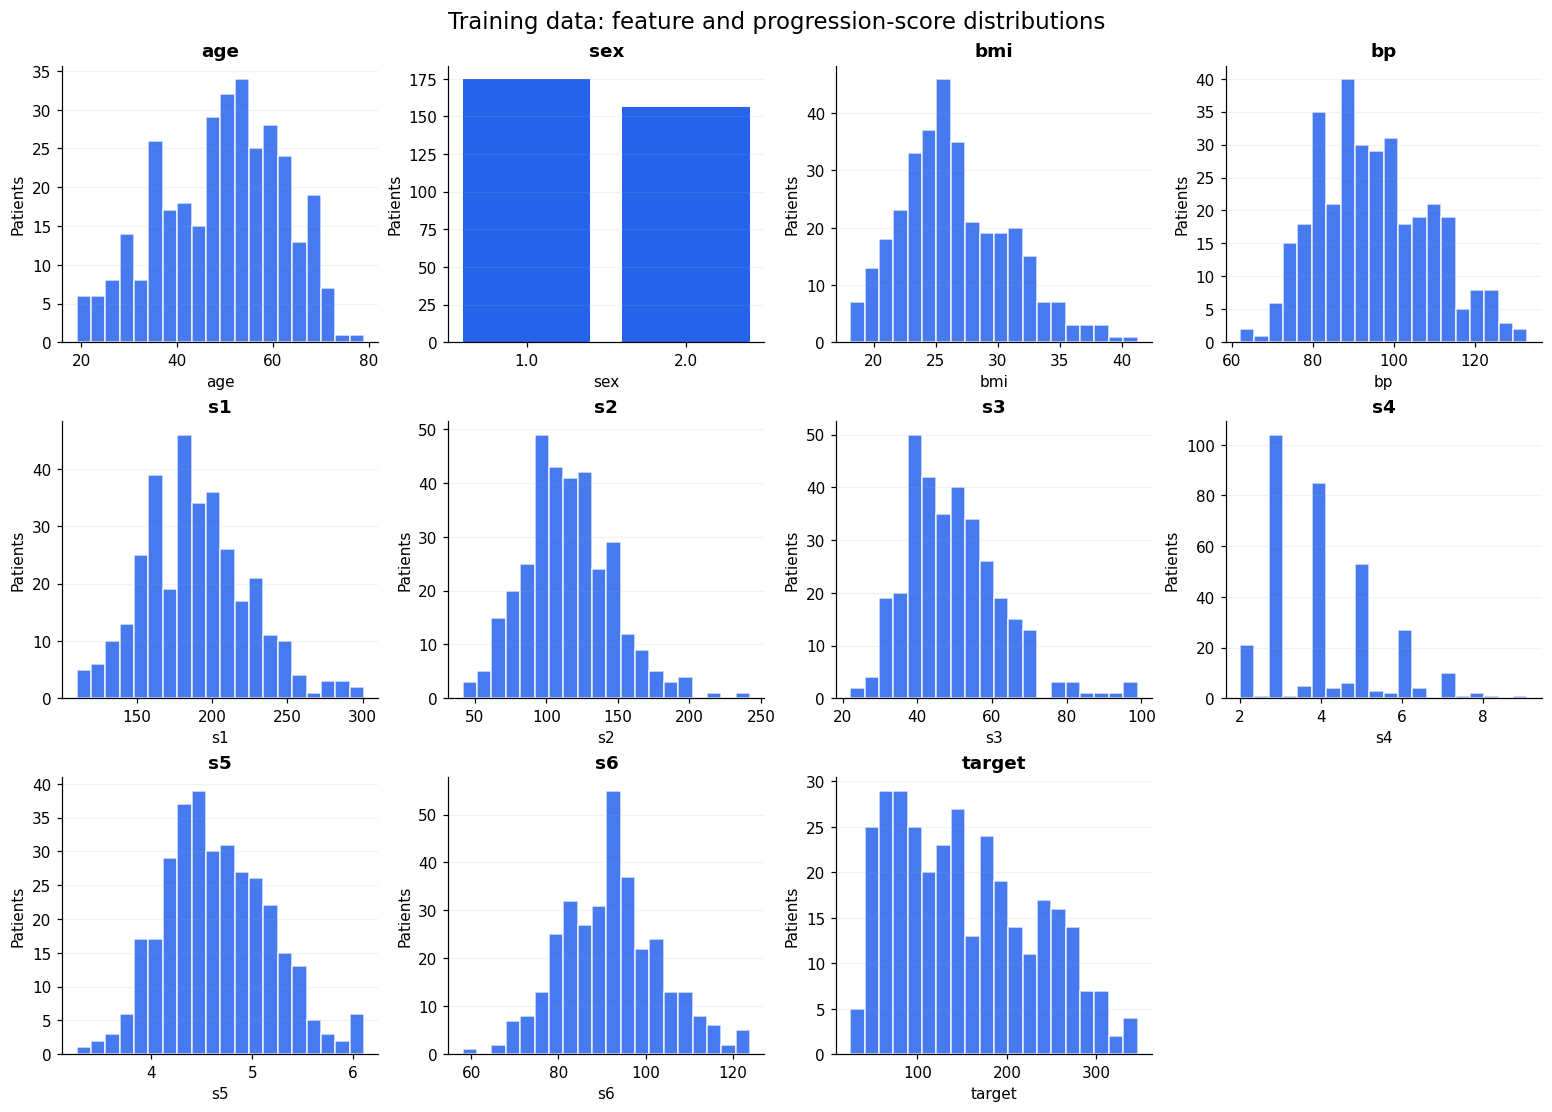

In [4]:
figure = plot_histograms(eda)
save_figure(figure, FIGURE_DIR / '01_training_distributions.png')
plt.show()


BMI and several serum measurements have longer upper tails, while sex has two distinct categories. Feature ranges differ substantially, particularly serum cholesterol versus the log-like `s5` measurement; this motivates training-only scaling for kNN and polynomial models. A non-normal predictor or response is not, by itself, a data error or a reason for deletion.

### Scatter plots


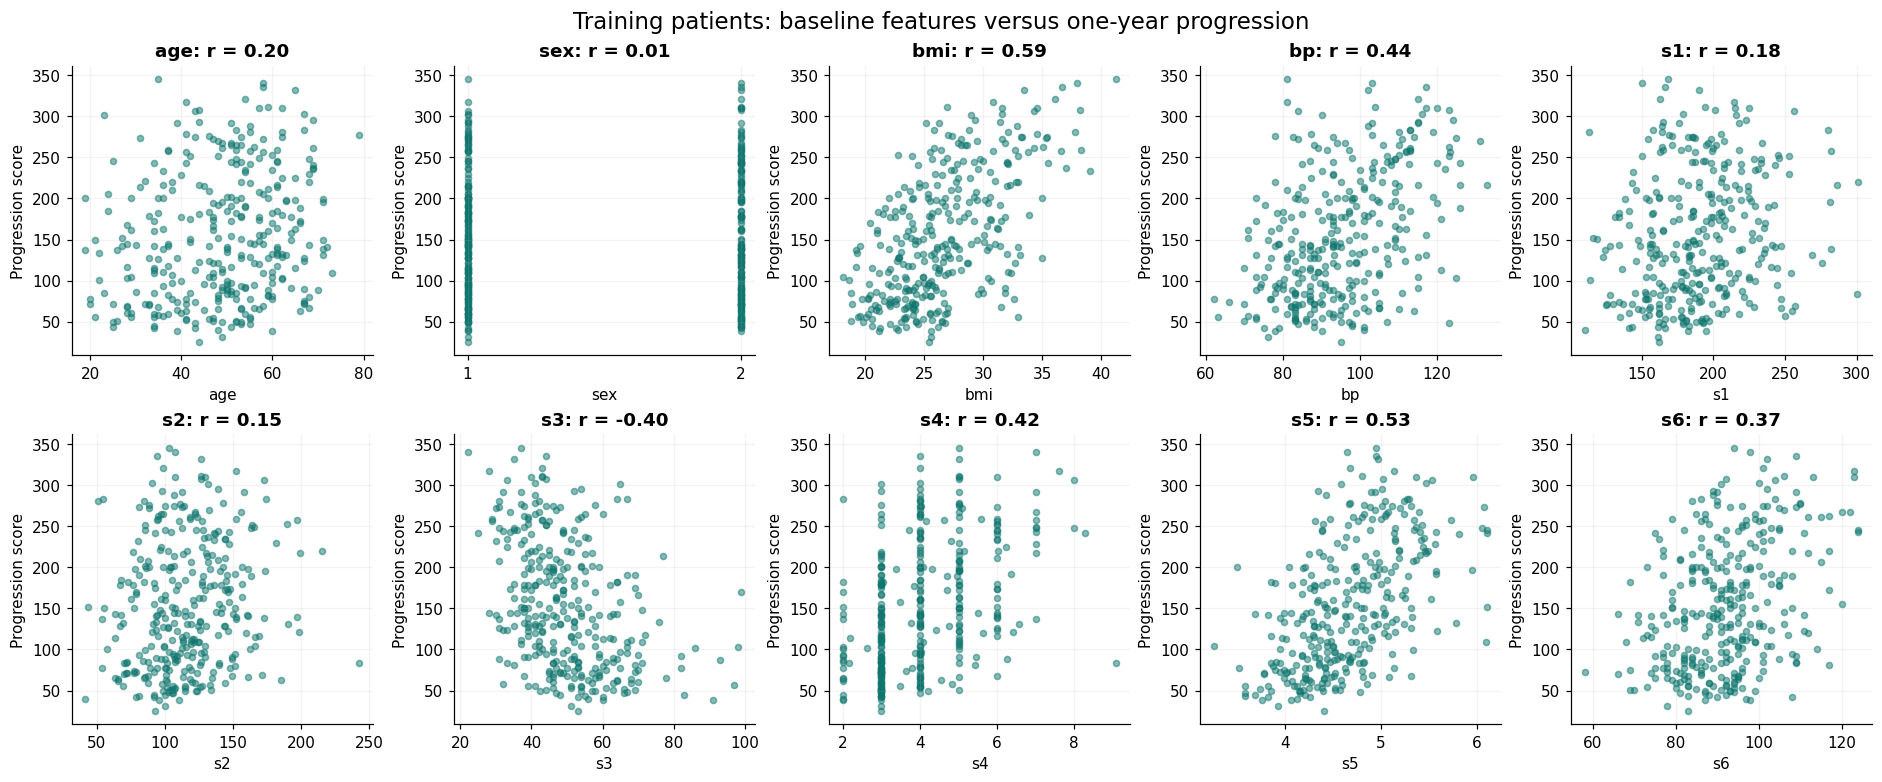

In [5]:
figure = plot_scatter(eda)
save_figure(figure, FIGURE_DIR / '02_training_scatter.png')
plt.show()


BMI and `s5` have the strongest positive marginal linear associations with progression in training data, approximately **0.591** and **0.534**. `s3` has a negative association, approximately **−0.397**. Large vertical variation at similar BMI values suggests a limitation for BMI-only prediction. The plots support investigating nonlinear relationships but do not establish that a higher-degree polynomial is superior. Associations do not demonstrate causation.

### Correlation matrix


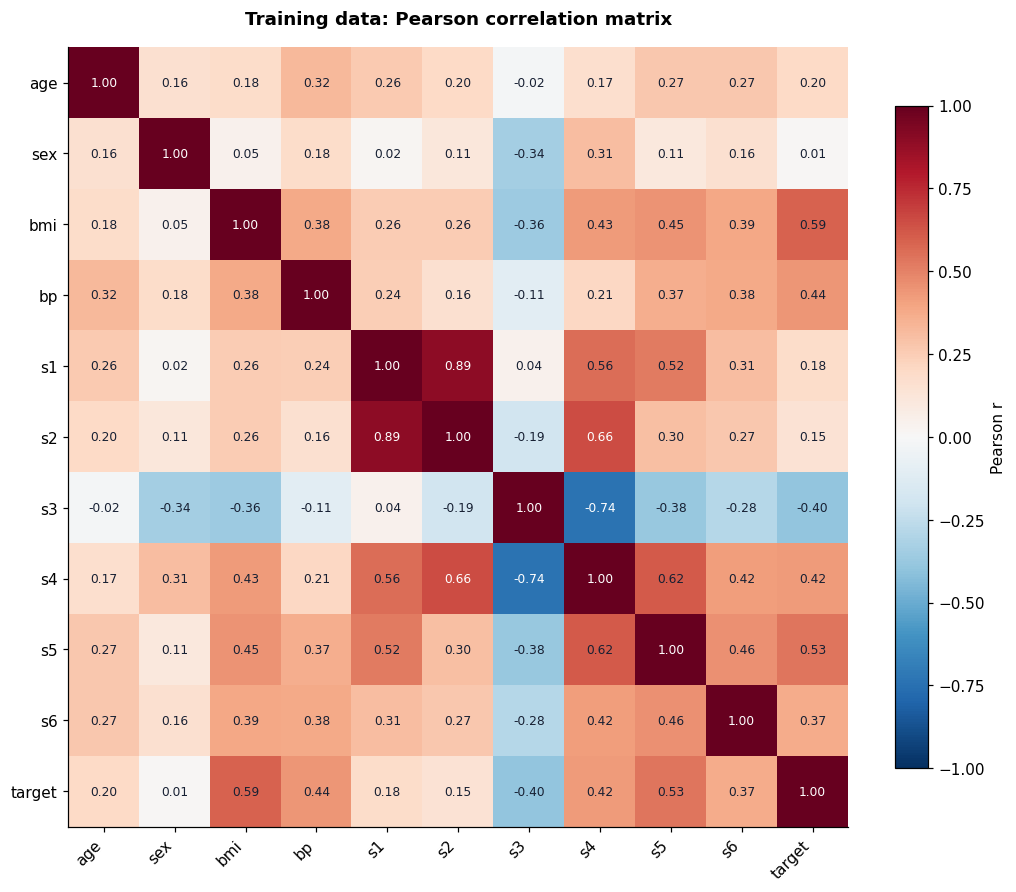

,Pearson r
bmi,0.591
s5,0.534
bp,0.442
s4,0.424
s6,0.371
age,0.198
s1,0.182
s2,0.147
sex,0.014
s3,-0.397


In [6]:
figure = plot_correlations(eda)
save_figure(figure, FIGURE_DIR / '03_training_correlations.png')
plt.show()
display(eda.corr(numeric_only=True)[TARGET].drop(TARGET).sort_values(ascending=False).to_frame('Pearson r'))


The **0.893** training correlation between `s1` and `s2` indicates overlapping linear information. Marginal association for sex is near zero (**0.014**), but that does not rule out interactions. All ten baseline features are retained in Part 3: dropping them solely on marginal correlation could remove conditional information. The correlation structure and redundant binary polynomial terms motivate regularized multivariate polynomials. No feature selection uses held-out outcomes.


## 4. Cleaning and justification


In [7]:
display(quality_report(df))
print('Exact duplicate records:', int(df.duplicated().sum()))
print('Repeated feature profiles:', int(df.drop(columns=TARGET).duplicated().sum()))
print('Constant predictors:', [name for name in feature_names if df[name].nunique() <= 1])
display(iqr_summary(eda).round(3))
assert df_clean.equals(df)


,dtype,missing,non_finite,unique_values
age,float64,0,0,58
sex,float64,0,0,2
bmi,float64,0,0,163
bp,float64,0,0,100
s1,float64,0,0,141
s2,float64,0,0,302
s3,float64,0,0,63
s4,float64,0,0,66
s5,float64,0,0,184
s6,float64,0,0,56


Exact duplicate records: 0
Repeated feature profiles: 0
Constant predictors: []


,Lower fence,Upper fence,Flagged values
age,9.000,89.000,0
bmi,14.500,38.500,2
bp,52.500,136.500,0
s1,95.250,277.250,7
s2,36.150,192.550,6
s3,17.000,81.000,9
s4,0.000,8.000,2
s5,3.207,6.114,0
s6,61.500,121.500,6


There are **no missing or non-finite values, exact duplicate records, repeated feature profiles, or constant predictors**. Both sex codes match the source representation. Therefore, no imputation, record removal, clipping, or feature deletion is justified by these checks. The working copy preserves all 442 patients.

The training-only 1.5 × IQR check flags some extreme measurements. These observations are retained: a statistical outlier flag does not establish a recording error, and extreme patients may be important to the prediction task. No outcome values are removed to improve metrics. Standardization is preprocessing fitted within each training pipeline, not a cleaning operation fitted to the full dataset.


## 5. Train–validation–test allocation
`split_dataset()` first reserves 25% of patient indices, then allocates 60% of that reserve to test and 40% to validation. The nominal proportions are thus 75%, 15%, and 10%. Whole-patient rounding gives 331 / 44 / 67. `random_state=42` fixes the random allocation. The split is not stratified on arbitrary bins of the continuous response.


In [8]:
display(split_summary(split).round(2))
X_train, X_val, X_test = split.X_train, split.X_val, split.X_test
y_train, y_val, y_test = split.y_train, split.y_val, split.y_test
groups = [set(X.index) for X in [X_train, X_val, X_test]]
assert groups[0].isdisjoint(groups[1]) and groups[0].isdisjoint(groups[2])
assert groups[1].isdisjoint(groups[2])
assert set.union(*groups) == set(df.index)
for X, y in [(X_train, y_train), (X_val, y_val), (X_test, y_test)]:
    assert X.index.equals(y.index) and TARGET not in X.columns
print('Disjoint patient groups, complete coverage, and feature/response alignment verified.')


,Subset,Patients,Requested (%),Actual (%)
0,Training,331,75,74.89
1,Validation,44,10,9.95
2,Test,67,15,15.16


Disjoint patient groups, complete coverage, and feature/response alignment verified.


# Part 2 — Univariate BMI polynomial regression
## 6. Six polynomial models, degrees 0–5
For standardized BMI `z = (BMI − training mean BMI) / training std BMI`, each degree-d model fits `b0 + b1*z + ... + bd*z^d` by ordinary least squares. The pipeline standardizes BMI, generates powers with `PolynomialFeatures(include_bias=True)`, and uses `LinearRegression(fit_intercept=False)` so the constant is represented exactly once. Degree 0 estimates the training response mean and serves as the baseline. Standardization improves conditioning without adding another original feature.

The source modules specify **all six BMI models and all eight Part 3 candidates before evaluation**. `run_experiment()` fits them using training patients, selects winners using validation MAE, and only then evaluates the chosen BMI model and each chosen multivariate family model on test patients. It returns cached test predictions for diagnostics. This fixed assignment split supports an internal comparison; it is not external validation or a new independent test study for each part.


In [9]:
result = run_experiment(split)
export_results(result, split, TABLE_DIR)
print('BMI candidates:', len(result['bmi_candidates']))
print('Multivariate candidates:', len(result['multivariate_candidates']))


BMI candidates: 6
Multivariate candidates: 8


## 7. Training and validation comparison
Each degree has its own row and all six required metrics. MAPE is expressed as a percentage; selection uses unrounded MAE.


In [10]:
bmi_table = result['bmi_table'].drop(columns=['Family', 'Order'])
display(bmi_table.round(3))


,Model,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,BMI degree 0,-0.000,66.202,62.827,-0.107,66.057,71.264
1,BMI degree 1,0.350,52.288,48.363,0.331,47.208,47.060
2,BMI degree 2,0.351,52.207,48.299,0.332,47.214,47.240
3,BMI degree 3,0.351,52.199,48.281,0.332,47.185,47.223
4,BMI degree 4,0.353,52.093,48.053,0.341,46.090,46.050
5,BMI degree 5,0.354,52.059,48.004,0.350,45.462,45.175


The constant model has training R² approximately zero and validation R² **−0.107**. Degree 1 improves validation MAE from **66.06** to **47.21**, establishing a benefit from BMI relative to the constant predictor. Degrees 1–3 have nearly identical validation performance. Degree 5 reduces validation MAE to **45.46**, but training R² rises only from approximately **0.350** at degree 1 to **0.354** at degree 5. The additional flexibility contributes modest incremental benefit on this split.


## 8. Best BMI model


In [11]:
bmi_best = result['bmi_winner']
model = bmi_best.estimator
display(result['bmi_table'].loc[result['bmi_table']['Model'] == bmi_best.name].drop(columns='Order').round(3))
print('Selected by minimum validation MAE:', bmi_best.name)


,Model,Family,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
5,BMI degree 5,BMI polynomial,0.354,52.059,48.004,0.35,45.462,45.175


Selected by minimum validation MAE: BMI degree 5


**Degree 5** is selected. It also has the highest validation R² (**0.350**) and lowest validation MAPE (**45.18%**), so the three validation metrics agree here. Its modest margin over simpler models and the small 44-patient validation set limit confidence that the same degree would win on another split.


## 9. Test evaluation of the selected BMI model


In [12]:
bmi_test = result['test_table'].loc[result['test_table']['Model'] == bmi_best.name]
display(bmi_test.drop(columns='Family').round(3))


,Model,R2,MAE,MAPE (%)
0,BMI degree 5,0.267,51.75,43.027


Test **R² = 0.267**, **MAE = 51.75**, and **MAPE = 43.03%** indicate substantial unexplained variation and individual error. R² represents improvement in squared error relative to the test target's mean-reference prediction, not a fraction of correctly classified patients. Test MAE is worse than validation MAE, while test MAPE is lower: relative and absolute errors weight outcomes differently and need not move together.


## 10. Fitted curve over each data subset
The panels use the same training-fitted model. Validation and test data do not fit separate curves. Grey edges indicate BMI values beyond the training range.


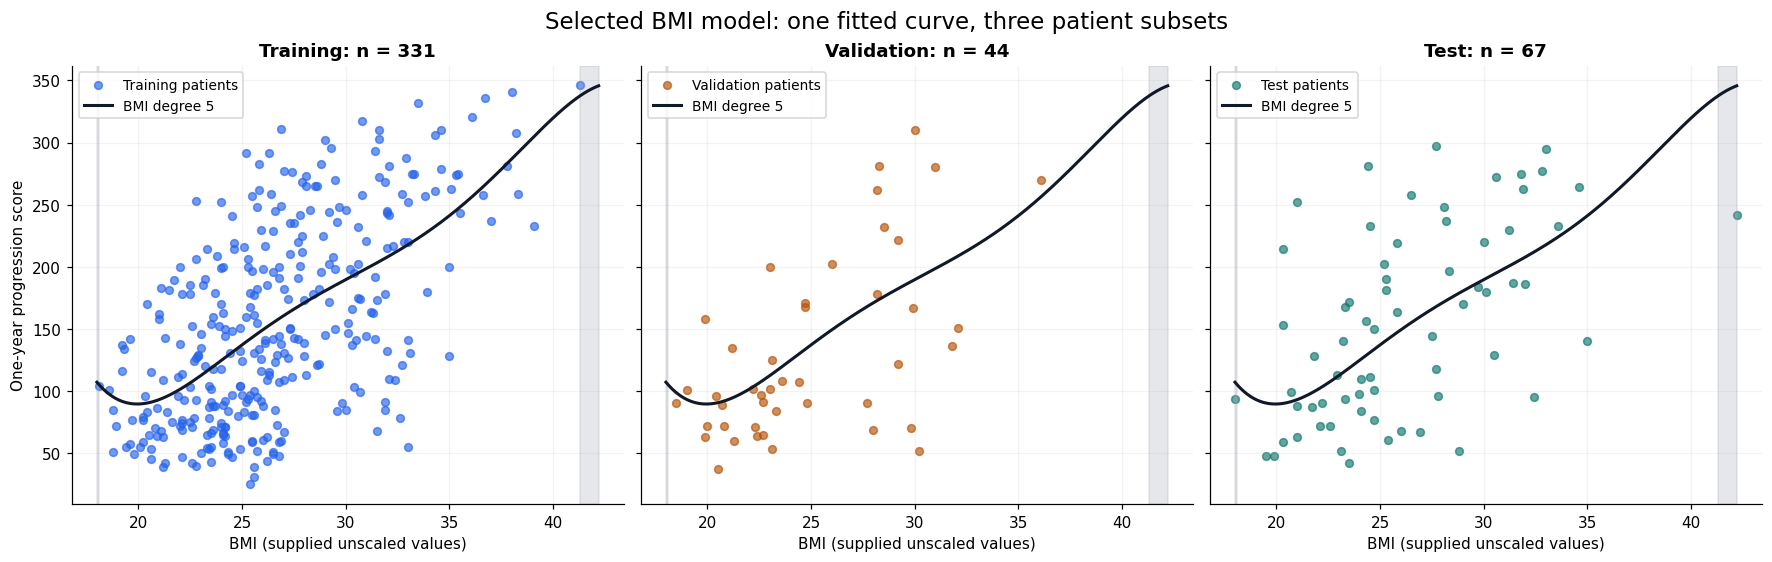

In [13]:
figure = plot_bmi_fit(bmi_best, split)
save_figure(figure, FIGURE_DIR / '04_selected_bmi_fit.png')
plt.show()


## 11. Equation of the best BMI model
The equation, with coefficients displayed to two decimal places, is:

\[
\widehat{y}=156.10+49.11z-8.70z^2-1.04z^3+3.55z^4-0.70z^5,
\qquad z=\frac{\mathrm{BMI}-26.59154079}{4.37364958}.
\]

The coordinate's mean and scale are displayed to greater precision. The regression constant is the predicted score at the training mean BMI, not the prediction for raw BMI zero. Every metric and prediction uses the fitted full-precision coefficients. Rounding a raw-BMI expansion to two decimals would erase small high-order coefficients; the standardized representation avoids that major distortion.


In [14]:
bmi_coefficients = polynomial_coefficients(bmi_best)
display(bmi_coefficients.assign(Coefficient=bmi_coefficients['Coefficient'].map(lambda x: f'{x:.2f}')))
scaler = model.named_steps['scale']
coefficients = model.named_steps['regression'].coef_
equation_grid = pd.DataFrame({'bmi': np.linspace(X_train['bmi'].min(), X_train['bmi'].max(), 500)})
z = (equation_grid['bmi'].to_numpy() - scaler.mean_[0]) / scaler.scale_[0]
exact = Polynomial(coefficients)(z)
assert np.allclose(exact, model.predict(equation_grid), atol=1e-10)
rounded = Polynomial(np.round(coefficients, 2))(z)
print(f'Maximum rounding difference over the inspected training-range grid: {np.max(abs(exact-rounded)):.3f} score units')


,Term,Coefficient
0,1,156.10
1,z_bmi,49.11
2,z_bmi^2,-8.70
3,z_bmi^3,-1.04
4,z_bmi^4,3.55
5,z_bmi^5,-0.70


Maximum rounding difference over the inspected training-range grid: 1.337 score units


The rounded equation differs by at most **1.34 score units on this 500-point training-range grid**. This is small relative to test MAE but is not a clinical error tolerance or a bound outside the inspected interval. Exact coefficients and scaling constants are exported under `reports/tables/`.


## 12. Expected progression at a chosen BMI


In [15]:
chosen_bmi = 25.0
new_bmi = pd.DataFrame({'bmi': [chosen_bmi]})
expected_progression = float(model.predict(new_bmi)[0])
print(f'BMI {chosen_bmi:.1f}: expected one-year progression score = {expected_progression:.2f}')


BMI 25.0: expected one-year progression score = 137.19


The expected score is **137.19** for BMI 25.0, which is inside the training BMI range. The pipeline performs all transformations; the new input is supplied in raw BMI values. This is a point estimate in score units, not a percentage risk.


## 13. Trainable parameters
A degree-d univariate polynomial has **d + 1 fitted regression coefficients**, including one constant. `get_feature_names_out()` reveals the actual generated terms.


In [16]:
parameter_rows = []
for candidate in result['bmi_candidates']:
    poly = candidate.estimator.named_steps['poly']
    terms = poly.get_feature_names_out(['z_bmi'])
    count = candidate.estimator.named_steps['regression'].coef_.size
    parameter_rows.append({'Model': candidate.name, 'Generated terms': ', '.join(terms), 'Coefficients': count})
display(pd.DataFrame(parameter_rows))


,Model,Generated terms,Coefficients
0,BMI degree 0,1,1
1,BMI degree 1,"1, z_bmi",2
2,BMI degree 2,"1, z_bmi, z_bmi^2",3
3,BMI degree 3,"1, z_bmi, z_bmi^2, z_bmi^3",4
4,BMI degree 4,"1, z_bmi, z_bmi^2, z_bmi^3, z_bmi^4",5
5,BMI degree 5,"1, z_bmi, z_bmi^2, z_bmi^3, z_bmi^4, z_bmi^5",6


Degrees 0–5 therefore fit **1, 2, 3, 4, 5, and 6** coefficients, respectively. StandardScaler's training mean and scale are preprocessing statistics; the polynomial degree is a selected hyperparameter. Neither is counted as an additional regression coefficient.


## 14. BMI model failure analysis and conclusion
Residuals are defined as **actual minus prediction**: positive values indicate underprediction and negative values indicate overprediction. The score intervals below are descriptive outcome bins, not clinical risk categories or inputs to the model.


,Patients,MAE,Mean_residual,MAPE_percent
Observed score band,,,,
Below 100,23,48.615,-47.960,75.211
100 to below 200,24,31.899,1.245,21.778
200 or above,20,79.178,68.806,31.514


,bmi,actual,predicted,residual,absolute_error,APE (%)
78,21.0,252.0,93.117,158.883,158.883,63.049
117,24.4,281.0,129.680,151.320,151.320,53.851
113,27.7,297.0,167.984,129.016,129.016,43.440
380,28.8,52.0,178.753,-126.753,126.753,243.755
218,20.3,214.0,90.023,123.977,123.977,57.933


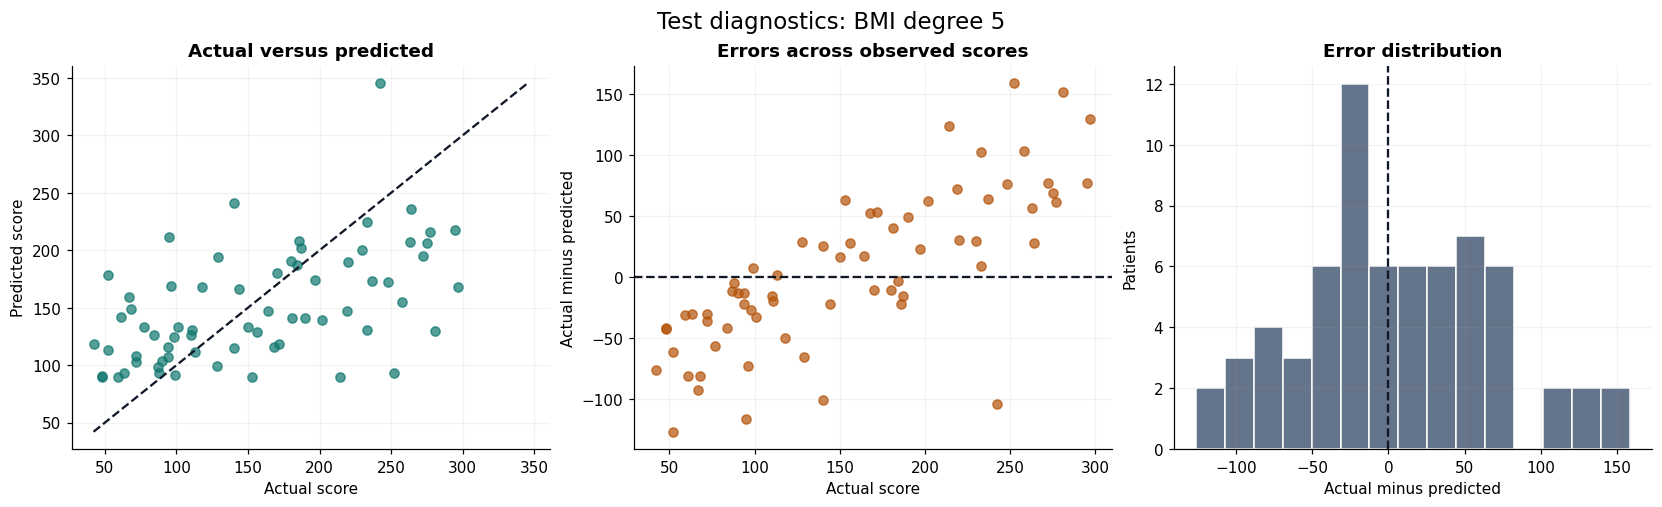

Hypothetical out-of-range BMI 50 prediction: -137.2


In [17]:
bmi_errors = result['diagnostics'][bmi_best.name]
display(result['diagnostic_bands'][bmi_best.name].round(3))
display(bmi_errors.sort_values('absolute_error', ascending=False)[
    ['bmi', 'actual', 'predicted', 'residual', 'absolute_error', 'APE (%)']
].head(5).round(3))
figure = plot_residuals(bmi_errors, bmi_best.name)
save_figure(figure, FIGURE_DIR / '05_bmi_test_diagnostics.png')
plt.show()
print('Hypothetical out-of-range BMI 50 prediction:', round(float(model.predict(pd.DataFrame({'bmi': [50.0]}))[0]), 2))


The model overpredicts scores below 100 on average (mean residual **−47.96**) and underpredicts scores of 200 or above (mean residual **68.81**). High-score MAE is **79.18**, versus **31.90** for scores from 100 to below 200. Grouping by observed outcomes naturally exposes regression toward the middle and is descriptive, not proof of a causal mechanism.

The largest test error is **158.88**: BMI 21.0, actual score 252, prediction 93.12. Another patient has BMI 28.8, actual 52, and prediction 178.75, illustrating failure in the opposite direction. Similar BMI values cannot distinguish patients with different omitted measurements. A small mean residual would not establish accuracy because errors of opposite sign cancel.

The fitted training BMI range is **18.1–41.3**. At hypothetical BMI 50, the model predicts **−137.20**, outside the positive observed score range. This demonstrates unsupported polynomial extrapolation, not a claim about an actual patient. Sparse boundary data and unconstrained curve shape limit reliability even when a model improves average validation error.

**Conclusion:** Degree 5 wins this six-model comparison but offers only a modest improvement over the straight-line BMI model. Single-feature information loss, large errors for extreme outcomes, sensitivity to a small validation split, lack of prediction intervals, and lack of external or clinical validation limit its proposed screening use. From the classification-metrics workshop, missed clinically important cases and unnecessary flags have different consequences; regression scores alone do not quantify sensitivity or precision. From the KNN workshop, examining individual failures matters beyond an aggregate metric. From the logistic/log-loss workshop, a score must not be mistaken for a calibrated probability or a validated binary decision [8–10].


# Part 3 — Multivariate models
## 15. Feature policy and eight predeclared candidates
All **ten baseline features** are retained based on Step 3. No multivariate model-fit plots are required. Standardization is learned from training data for polynomial, kNN, and logistic pipelines; trees use supplied feature values because threshold splits do not require normalization.

| Family | Candidate 1 | Candidate 2 | Rationale |
|---|---|---|---|
| Multivariate polynomial | Degree 2, Ridge α = 1 | Degree 3, Ridge α = 1 | Compare nonlinear complexity; regularize correlated and redundant expanded terms. |
| Decision tree | Depth 3, minimum leaf size 5 | Depth 5, minimum leaf size 5 | Compare partition complexity with consistent leaf-size control. |
| kNN regression | k = 15, uniform weights | k = 5, uniform weights | Compare smoother versus more local averaging in standardized Euclidean distance. |
| Logistic classifier + score decoder | C = 0.1 | C = 1.0 | Compare stronger versus weaker default L2 regularization with identical training-derived labels and decoder. |

The multivariate polynomial pipelines standardize the ten inputs, generate all powers/interactions up to degree 2 or 3, standardize those terms, and fit Ridge regression. Ridge is a regularized polynomial least-squares model; α is fixed, not tuned on test data. The additional term scaling puts penalties on comparable column scales.


## 16. Training–validation comparison and selection (repeat Steps 7–8)
The logistic rows' R², MAE, and MAPE use **decoded predictions against original progression scores**. Their classification objective is evaluated separately in Step 20.


In [18]:
multi_table = result['multivariate_table']
display(multi_table.drop(columns='Order').round(3))
selected_names = [candidate.name for candidate in result['family_winners']]
display(multi_table.loc[multi_table['Model'].isin(selected_names),
                       ['Model', 'Family', 'Validation R2', 'Validation MAE', 'Validation MAPE (%)']].round(3))
multi_best = result['multivariate_winner']
print('Overall multivariate winner by validation MAE:', multi_best.name)


,Model,Family,Train R2,Train MAE,Train MAPE (%),Validation R2,Validation MAE,Validation MAPE (%)
0,Polynomial degree 2 (Ridge),Multivariate polynomial,0.599,39.292,34.748,0.459,40.125,40.448
1,Polynomial degree 3 (Ridge),Multivariate polynomial,0.792,27.132,24.398,0.034,53.222,55.338
2,Tree depth 3,Decision tree,0.509,44.656,39.019,0.362,42.706,42.844
3,Tree depth 5,Decision tree,0.665,34.481,29.852,0.253,47.607,47.132
4,kNN k=15,kNN,0.491,44.869,39.179,0.366,44.718,45.459
5,kNN k=5,kNN,0.568,40.839,35.060,0.326,44.245,41.800
6,Logistic C=0.1 (score adapter),Logistic score adapter,0.433,49.145,45.345,0.393,44.843,46.570
7,Logistic C=1 (score adapter),Logistic score adapter,0.446,48.198,44.189,0.398,43.580,45.007


,Model,Family,Validation R2,Validation MAE,Validation MAPE (%)
0,Polynomial degree 2 (Ridge),Multivariate polynomial,0.459,40.125,40.448
2,Tree depth 3,Decision tree,0.362,42.706,42.844
5,kNN k=5,kNN,0.326,44.245,41.800
7,Logistic C=1 (score adapter),Logistic score adapter,0.398,43.580,45.007


Overall multivariate winner by validation MAE: Polynomial degree 2 (Ridge)


The **degree-2 Ridge polynomial** has the lowest validation MAE (**40.12**) among all eight candidates. The family selections are degree 2, tree depth 3, kNN k = 5, and logistic C = 1 with score decoding. A different metric can favor another candidate: k = 15 has higher validation R² than k = 5, but k = 5 wins on the predeclared MAE criterion.

The cubic polynomial's training R² (**0.792**) greatly exceeds its validation R² (**0.034**), while MAE increases from **27.13** in training to **53.22** in validation. The deeper tree similarly worsens validation MAE despite lower training error. These gaps provide evidence of poor generalization from excess flexibility on this sample. Two fixed settings per family are an assignment comparison, not an exhaustive hyperparameter search.


## 17. Test results for validation-selected models (repeat Step 9)
Each family contributes its validation-selected candidate; nonselected settings are not compared on test data. The BMI winner is included as a reference. No refitting or switching of selected models occurs after test results are viewed.


In [19]:
display(result['test_table'].round(3))


,Model,Family,R2,MAE,MAPE (%)
0,BMI degree 5,BMI polynomial,0.267,51.750,43.027
1,Polynomial degree 2 (Ridge),Multivariate polynomial,0.433,43.669,36.561
2,Tree depth 3,Decision tree,0.449,45.802,39.726
3,kNN k=5,kNN,0.471,42.209,34.653
4,Logistic C=1 (score adapter),Logistic score adapter,0.445,45.996,41.083


The selected degree-2 model achieves **R² 0.433, MAE 43.67, MAPE 36.56%**, improving over BMI-only test MAE 51.75. The selected kNN k = 5 has the lowest observed test MAE (**42.21**) and highest test R² (**0.471**) among these selected models. This does **not** retroactively replace the validation-based winner. Different patient samples can reverse small rankings, and the same fixed test set is used for all required family comparisons. There is no independent external validation cohort.


## 18. Model equations and prediction rules (repeat Step 11)
### Selected polynomial
For input feature j, define \(z_j=(x_j-\mu_j)/\sigma_j\), using training statistics. Let \(\phi_k(z)\) enumerate the linear, squared, and pairwise interaction terms. Each term is then standardized to \(t_k=(\phi_k(z)-m_k)/s_k\). The selected degree-2 Ridge model is:

\[
\widehat y=\beta_0+\sum_{k=1}^{65}\beta_k t_k.
\]

The coefficient table below supplies the numerical equation with two-decimal display precision. Exact coefficients, input scaling, and term scaling are exported as CSVs. Those three tables together specify the complete model; raw-feature coefficients are not implied by the standardized-term coefficients.


In [20]:
poly_best = next(candidate for candidate in result['family_winners'] if candidate.family == 'Multivariate polynomial')
poly_coefficients = polynomial_coefficients(poly_best)
with pd.option_context('display.max_rows', 100):
    display(poly_coefficients.assign(Coefficient=poly_coefficients['Coefficient'].map(lambda x: f'{x:.2f}')))

poly_pipeline = poly_best.estimator
X_check = X_train.copy()
transformed = poly_pipeline[:-1].transform(X_check)
regression = poly_pipeline.named_steps['regression']
manual_prediction = regression.intercept_ + transformed @ regression.coef_
assert np.allclose(manual_prediction, poly_pipeline.predict(X_check), atol=1e-10)
rounded_prediction = round(float(regression.intercept_), 2) + transformed @ np.round(regression.coef_, 2)
print(f'Maximum coefficient-rounding error on training patients: {np.max(abs(manual_prediction-rounded_prediction)):.3f}')
display(pd.DataFrame({'Feature': feature_names,
                      'Training mean': poly_pipeline.named_steps['scale'].mean_,
                      'Training scale': poly_pipeline.named_steps['scale'].scale_}))


,Term,Coefficient
0,intercept,154.34
1,z_age,6.21
2,z_sex,-6.76
3,z_bmi,18.63
4,z_bp,20.37
5,z_s1,-7.45
6,z_s2,0.90
7,z_s3,-17.54
8,z_s4,-1.42
9,z_s5,30.08


Maximum coefficient-rounding error on training patients: 0.079


,Feature,Training mean,Training scale
0,age,48.798,12.771
1,sex,1.471,0.499
2,bmi,26.592,4.374
3,bp,95.023,13.892
4,s1,189.547,34.930
5,s2,115.470,30.804
6,s3,49.627,12.768
7,s4,4.094,1.308
8,s5,4.660,0.526
9,s6,92.045,11.445


### Selected tree, kNN, and logistic models
- **Tree depth 3:** \(\widehat y(x)=\sum_{\ell=1}^{8}\overline y_\ell\mathbf{1}\{x\in R_\ell\}\). Each leaf region is defined by fitted feature thresholds, and each response is the training target mean in that leaf. `Tree_depth_3_rules.txt` supplies the readable fitted branches; the node CSV preserves full-precision thresholds and values.
- **kNN k = 5:** \(\widehat y(x)=\tfrac{1}{5}\sum_{i\in N_5(z)}y_i\). Neighbors are found by Euclidean distance in training-standardized ten-feature space. It has no single global slope equation.
- **Logistic C = 1:** \(p(x)=1/(1+e^{-\eta})\), where \(\eta=a+\sum_{j=1}^{10}w_jz_j\). For the original-score comparison, \(\widehat y(x)=\mu_0+(\mu_1-\mu_0)p(x)\). The fitted coefficients and decoding constants are shown below. The probability is for the exploratory above-training-median event.


In [21]:
logistic_best = next(candidate for candidate in result['family_winners']
                     if candidate.family == 'Logistic score adapter')
logistic_adapter = logistic_best.estimator
logit = logistic_adapter.classifier_.named_steps['logistic']
logit_equation = pd.DataFrame({
    'Term': ['intercept', *[f'z_{name}' for name in feature_names]],
    'Coefficient': np.r_[logit.intercept_, logit.coef_.ravel()],
})
display(logit_equation.round(2))
print('Training progression threshold:', logistic_adapter.threshold_)
print('Training class means, low then high:', logistic_adapter.class_means_)


,Term,Coefficient
0,intercept,0.09
1,z_age,0.05
2,z_sex,-0.58
3,z_bmi,0.59
4,z_bp,0.60
5,z_s1,-0.36
6,z_s2,-0.11
7,z_s3,-0.44
8,z_s4,0.20
9,z_s5,0.75


Training progression threshold: 142.0
Training class means, low then high: [ 88.10429448 218.61309524]


The probability decoder assumes that two fixed training class means adequately represent within-class scores. It does not model how the expected score varies within either band, and its predictions are bounded between those means. This is a deliberate, transparent approximation introduced only because the requested classifier family and the numerical target are otherwise incompatible.


## 19. Example predictions and fitted quantities (repeat Steps 12–13)
BMI alone is insufficient to call a ten-feature model. A **hypothetical complete profile** therefore uses training-feature medians, the training modal sex code, and BMI set to **25.0**. The profile is not presented as an observed patient or a clinically representative case. The same profile is supplied to all eight candidates.


In [22]:
display(result['example_profile'].T.rename(columns={0: 'Hypothetical input'}))
display(result['example_predictions'].round(2))
multivariate_prediction = float(multi_best.estimator.predict(result['example_profile'][multi_best.columns])[0])
print(f'Validation-selected multivariate model prediction: {multivariate_prediction:.2f} score units')
display(result['parameters'].round(3))


,Hypothetical input
age,50.000
sex,1.000
bmi,25.000
bp,93.000
s1,187.000
s2,113.000
s3,48.000
s4,4.000
s5,4.635
s6,92.000


,Model,Predicted score
0,Polynomial degree 2 (Ridge),142.38
1,Polynomial degree 3 (Ridge),129.94
2,Tree depth 3,111.57
3,Tree depth 5,99.27
4,kNN k=15,117.27
5,kNN k=5,131.00
6,Logistic C=0.1 (score adapter),161.98
7,Logistic C=1 (score adapter),165.61


Validation-selected multivariate model prediction: 142.38 score units


,Model,Response coefficients / values,Split thresholds,Training records retained,Interpretation
0,BMI degree 0,1,0,0,"One coefficient per polynomial term, including..."
1,BMI degree 1,2,0,0,"One coefficient per polynomial term, including..."
2,BMI degree 2,3,0,0,"One coefficient per polynomial term, including..."
3,BMI degree 3,4,0,0,"One coefficient per polynomial term, including..."
4,BMI degree 4,5,0,0,"One coefficient per polynomial term, including..."
5,BMI degree 5,6,0,0,"One coefficient per polynomial term, including..."
6,Polynomial degree 2 (Ridge),66,0,0,"One coefficient per polynomial term, including..."
7,Polynomial degree 3 (Ridge),286,0,0,"One coefficient per polynomial term, including..."
8,Tree depth 3,8,7,0,One mean per leaf; one threshold and a discret...
9,Tree depth 5,27,26,0,One mean per leaf; one threshold and a discret...


For ten original inputs, the number of polynomial coefficients including the intercept is \(\binom{10+d}{d}\): **66 for degree 2** and **286 for degree 3**. These count coefficient slots; exact collinearity means their independent unregularized degrees of freedom need not equal those counts. Ridge shrinks coefficients and makes the fit well defined, with effective flexibility depending on α and the design matrix.

The depth-3 tree stores **8 fitted leaf responses and 7 thresholds**, plus 7 discrete feature choices. The depth-5 tree stores **27 leaf responses and 26 thresholds**, plus 26 feature choices. These learned quantities are not interchangeable with polynomial coefficients. Each logistic classifier fits **11 coefficients** (ten weights and one intercept), plus the adapter's two training class means and training-median threshold. kNN fits no global regression coefficients but retains **331 ten-feature training records and their targets**; zero slope coefficients does not mean zero model complexity. Preprocessing statistics and hyperparameters are distinguished from fitted regression coefficients throughout.


## 20. Logistic classification evaluation
Both logistic candidates are reported on training and validation. Only the validation-MAE-selected logistic adapter is evaluated on test, and its classification results supplement rather than replace original-score metrics. The label threshold is the **training median of 142**; the probability decision threshold is **0.5**. These are different thresholds with different roles.


In [23]:
display(result['classification_table'].round(3))
logistic_test = result['classification_table'].query("Subset == 'Test'").iloc[0]
display(pd.DataFrame(
    [[int(logistic_test['TN']), int(logistic_test['FP'])],
     [int(logistic_test['FN']), int(logistic_test['TP'])]],
    index=['Actual below 142', 'Actual 142 or above'],
    columns=['Predicted below', 'Predicted above'],
))


,Model,Subset,Accuracy,Precision,Recall,F1,ROC AUC,Log-loss,TN,FP,FN,TP
0,Logistic C=0.1 (score adapter),Train,0.746,0.747,0.756,0.751,0.840,0.493,120,43,41,127
1,Logistic C=0.1 (score adapter),Validation,0.795,0.688,0.733,0.710,0.837,0.462,24,5,4,11
2,Logistic C=1 (score adapter),Train,0.752,0.753,0.762,0.757,0.841,0.488,121,42,40,128
3,Logistic C=1 (score adapter),Validation,0.795,0.688,0.733,0.710,0.832,0.463,24,5,4,11
4,Logistic C=1 (score adapter),Test,0.716,0.735,0.714,0.725,0.855,0.462,23,9,10,25


,Predicted below,Predicted above
Actual below 142,23,9
Actual 142 or above,10,25


The selected logistic classifier's test confusion matrix contains **23 true negatives, 9 false positives, 10 false negatives, and 25 true positives** for the exploratory event. Recall is **0.714**, precision **0.735**, ROC AUC **0.855**, and log-loss **0.462**. Ten above-threshold outcomes are missed at the fixed probability cutoff. These are not clinically defined missed diagnoses: the event is a sample-relative progression band.

Both logistic candidates have the same validation hard-label accuracy (**0.795**) but slightly different log-loss and ROC AUC. This mirrors the workshop distinction between hard decisions and probability quality. C = 0.1 has slightly better validation log-loss, while C = 1 wins the stated score-MAE rule. That objective conflict is reported rather than hidden. Threshold adjustment could change precision and recall but is not tuned on these test results.


## 21. Multivariate failure analysis and final conclusion (repeat Step 14)
The validation-selected degree-2 model is the main multivariate diagnostic subject. Outcome-band errors for all selected models are exported for comparison. They use cached predictions; no additional candidate settings are chosen from these diagnostics.


,Patients,MAE,Mean_residual,MAPE_percent
Observed score band,,,,
Below 100,23,41.129,-36.848,61.066
100 to below 200,24,35.341,-1.176,24.376
200 or above,20,56.584,31.029,23.001


,bmi,actual,predicted,residual,absolute_error,APE (%)
321,31.2,230.0,396.634,-166.634,166.634,72.450
380,28.8,52.0,185.804,-133.804,133.804,257.315
209,24.7,77.0,199.408,-122.408,122.408,158.972
395,26.5,258.0,150.026,107.974,107.974,41.850
199,22.2,90.0,197.902,-107.902,107.902,119.892


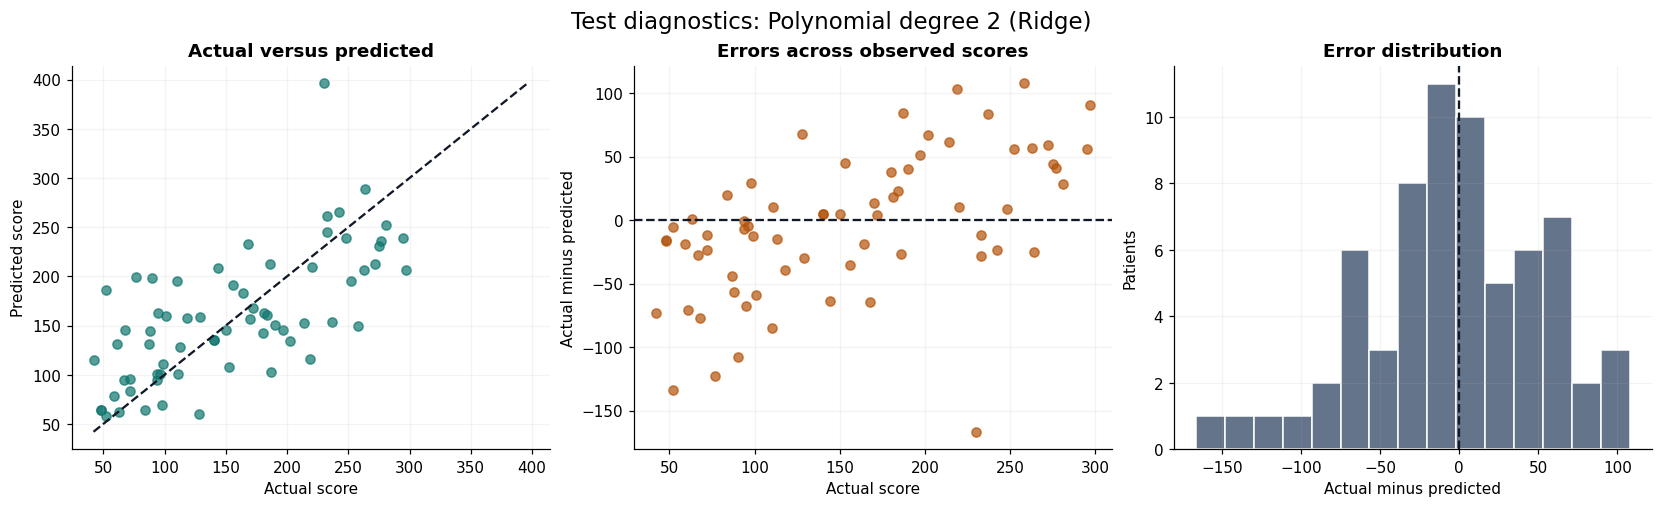

Largest multivariate absolute test error: 166.63
Mean multivariate test residual: -3.81


In [24]:
multi_errors = result['diagnostics'][multi_best.name]
display(result['diagnostic_bands'][multi_best.name].round(3))
display(multi_errors.sort_values('absolute_error', ascending=False)[
    ['bmi', 'actual', 'predicted', 'residual', 'absolute_error', 'APE (%)']
].head(5).round(3))
figure = plot_residuals(multi_errors, multi_best.name)
save_figure(figure, FIGURE_DIR / '06_multivariate_test_diagnostics.png')
plt.show()
print('Largest multivariate absolute test error:', round(multi_errors['absolute_error'].max(), 2))
print('Mean multivariate test residual:', round(multi_errors['residual'].mean(), 2))


### Where the models fail
The selected multivariate polynomial reduces high-score test MAE from the BMI model's **79.18** to **56.58**, but substantial error remains. It overpredicts the below-100 band on average (mean residual **−36.85**) and underpredicts the 200-or-above band (mean residual **31.03**). The middle band's MAE is **35.34**. These outcome-conditioned summaries describe the fitted model's errors; they do not establish a cause or identify a group knowable before outcomes occur.

Its largest individual test error is **166.63** units: a patient with actual progression **230** receives a prediction of **396.63**. That prediction exceeds the largest observed score of 346, demonstrating that an unconstrained polynomial can produce poorly supported outputs even when average error improves. Another patient with actual score **52** receives **185.80**. Improvement in average MAE does not imply improvement for every patient.

The cubic polynomial and deeper tree demonstrate overfitting on validation. Ridge reduces coefficient instability but does not guarantee useful generalization or prevent polynomial extrapolation. Trees make abrupt changes at split thresholds and can be unstable with small changes in data. kNN depends on distance scaling and local sample density; it averages training outcomes and can underpredict extreme new outcomes. The logistic score decoder compresses predictions between two class means, making extreme scores structurally difficult to predict even when the binary event is reasonably ranked.

### Performance and selection
The degree-2 Ridge polynomial is the **validation-selected model**, with test MAE **43.67**, compared with **51.75** for the selected BMI-only polynomial. This suggests value from additional baseline measurements on this split. kNN's lower test MAE (**42.21**) is a descriptive test result, not a new selection criterion. The experiment does not establish that one family dominates across populations or random splits.

### Limitations and workshop implications
The small 44-patient validation and 67-patient test samples make rankings uncertain. There is no external validation, temporal assessment, repeated-split uncertainty estimate, individual prediction interval, or clinical definition linking score error to a screening decision. Models use baseline measurements without treatment history or later interventions, and associations are not causal. All ten features are retained, but inclusion does not prove clinical relevance or subgroup fairness. The logistic threshold and decoder are experimental assumptions required to reconcile classification with the numerical assignment target; their metrics cannot be presented as validated diabetes-risk screening performance.

The classification-metrics workshop motivates examining false negatives, precision–recall tradeoffs, and probability ranking rather than accuracy alone. The KNN workshop motivates training-only scaling, neighbor sensitivity, individual error inspection, and a reusable pipeline. The logistic/log-loss workshop motivates treating probabilities and labels separately and penalizing confidently incorrect probabilities. These lessons support further training-only cross-validation and clinically defined outcomes, followed by genuinely independent validation before any screening application. The current results support an educational comparison of predictive methods, with a documented validation-based choice and explicit failure modes.


## References
1. [scikit-learn: Diabetes dataset description](https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset).
2. [scikit-learn: load_diabetes API](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).
3. [scikit-learn: Regression and classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html).
4. [scikit-learn: PolynomialFeatures](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html).
5. [scikit-learn: Ridge regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
6. [scikit-learn: LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
7. [scikit-learn: Data leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
8. Course workshop: **Performance Metrics for Classification**, supplied as `classification_metrics_answered.ipynb`; adapted from Géron's Chapter 3 classification notebook.
9. Course workshop: **K-Nearest Neighbors Workshop**, supplied as `KNearestNeighbors_Workshop.ipynb`, including feature scaling, neighbor count, and the ML Pipeline Pattern.
10. Course exercise: **Logistic Regression & Log-Loss — Pass/Fail Workshop**, supplied as `LogisticRegression_LogLoss_Independent.ipynb`, based on the instructor's pass/fail observations.
11. Assignment report-structure reference: [CSCN8010 notebook structure](https://github.com/CSCN8010/CSCN8010/blob/main/class_notebooks/notebook_structure/notebook_structure.ipynb).
